In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## dataset-composition

**Figure 1: Composition of the instruction-tuning dataset by source.** Each wedge is a source's share of the 1.24M examples. Web forums (38%) and textbooks (24%) together make up 62% of the data.

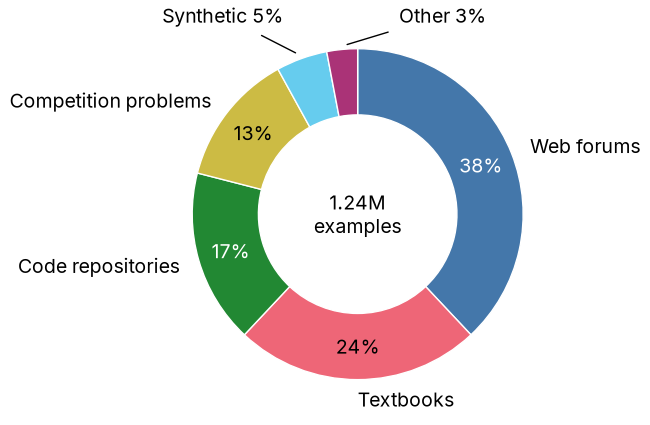

In [2]:
with open("../dataset-composition.json") as f:
    data = json.load(f)
names = list(data["sources"])
shares = list(data["sources"].values())
series_colors = [colors[f"series-{i + 1}"] for i in range(len(names))]

fig, ax = plt.subplots(figsize=(3.25, 3.25))
wedges, _ = ax.pie(shares, colors=series_colors, startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.4, edgecolor="white", linewidth=0.5))
for w, name, share, color in zip(wedges, names, shares, series_colors):
    mid = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(mid), np.sin(mid)
    ha = "left" if x > 0 else "right"
    if share < 0.06:
        label_x = {"Synthetic": -0.45, "Other": 0.25}[name]
        ax.annotate(f"{name} {share:.0%}", (1.02 * x, 1.02 * y), xytext=(label_x, 1.2),
                    ha="left" if label_x > 0 else "right", va="center",
                    arrowprops=dict(arrowstyle="-", color=colors["ink"], linewidth=0.5))
        continue
    lightness = np.dot(plt.matplotlib.colors.to_rgb(color), [0.299, 0.587, 0.114])
    ax.text(0.8 * x, 0.8 * y, f"{share:.0%}", ha="center", va="center",
            color="white" if lightness < 0.5 else "black")
    ax.annotate(name, (1.02 * x, 1.02 * y), xytext=(1.12 * x, 1.12 * y), ha=ha, va="center")
ax.text(0, 0, f"{data['total_examples'] / 1e6:.2f}M\nexamples", ha="center", va="center")

fit_height(fig, ax)
fig.savefig("dataset-composition.pdf")
fig.savefig("dataset-composition.png")
plt.show()